In [2]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

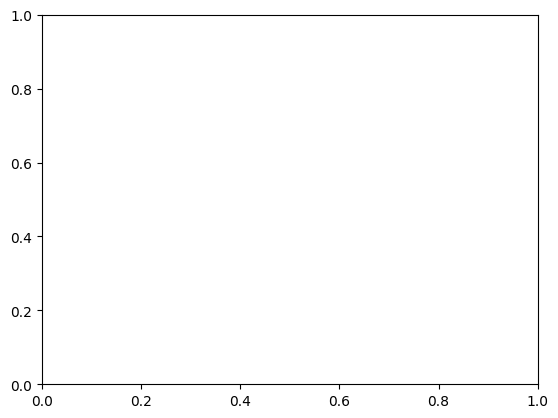

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

plt.show()

In [13]:
from tqdm import tqdm
from sklearn.metrics import f1_score, recall_score, precision_score
import torch.nn.functional as F

f1max = -1

def run_epoch(mdl, opt, loss, dataloader, is_train=True):
    global f1max
    mdl.train(is_train)
    total_loss = 0.0
    
    all_labels = []
    all_predictions = []
    
    with torch.set_grad_enabled(is_train):
        for x, y in tqdm(dataloader):
            x = x.to(device)
            y = y.to(device)
            
            y_pred = mdl(x)
            
            l = loss(y_pred, y)
                
            if (is_train):
                opt.zero_grad()
                l.backward()
                
                opt.step()
            
            
            total_loss += l.item() # loss           
            correct_idx = y.detach().cpu().numpy()
            all_labels.extend(correct_idx)

            predicted_idx = torch.argmax(F.softmax(y_pred.detach(), dim=1), dim=1).cpu().numpy()
            all_predictions.extend(predicted_idx)
            if f1max < float(f1_score(all_labels, all_predictions, average='macro')) and is_train:
                f1max = float(f1_score(all_labels, all_predictions, average='macro'))
                torch.save(alex_net_model.state_dict(), f'C:/Users/sasha/Desktop/проекты/YML NN/walexnetmodmaxf1.pth') 
    
    return {"Loss": total_loss / len(dataloader.dataset), "F1": f1_score(all_labels, all_predictions, average='macro'), "Recall": recall_score(all_labels, all_predictions, average='macro'), "Precision": precision_score(all_labels, all_predictions, average='macro')}

In [14]:
import numpy as np

def subplot_metrics(metrics, title, num_epochs):
    plt.title(title)
    
    x = np.arange(len(metrics["Train"]))
    
    for lbl, hst in metrics.items():
        plt.plot(x, hst, label=lbl)
    
    plt.grid()
    plt.xticks(np.arange(num_epochs))
    plt.legend()

def plot_metrics(metrics_hist, num_epochs):
    plt.figure(figsize=(16, 8.5))
    
    plt.subplot(2, 2, 1)
    subplot_metrics(metrics_hist["Loss"], f'Loss = {metrics_hist["Loss"]["Train"][-1]}, {metrics_hist["Loss"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 2)
    subplot_metrics(metrics_hist["F1"], f'F1 = {metrics_hist["F1"]["Train"][-1]}, {metrics_hist["F1"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 3)
    subplot_metrics(metrics_hist["Recall"], f'Recall = {metrics_hist["Recall"]["Train"][-1]}, {metrics_hist["Recall"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 4)
    subplot_metrics(metrics_hist["Precision"], f'Precision = {metrics_hist["Precision"]["Train"][-1]}, {metrics_hist["Precision"]["Test"][-1]}', num_epochs)
    
    plt.subplots_adjust(wspace=0.5)
    plt.show()

In [15]:
from IPython.display import clear_output

def run_train_loop(mdl, opt, loss, train_loader, val_loader, num_epochs, is_train=True):
    train_hist = []
    val_hist = []
    metrics_hist = {"Loss": {"Train": [], "Test": []}, "F1":  {"Train": [], "Test": []}, "Recall":  {"Train": [], "Test": []}, "Precision":  {"Train": [], "Test": []}}
    
    for e in range(num_epochs):
        print("Trainin...")
        train_metrics = run_epoch(mdl, opt, loss, train_loader, is_train)
        for key in metrics_hist.keys():
            metrics_hist[key]["Train"].append(train_metrics[key])
        
        print("Validating...")
        val_metrics = run_epoch(mdl, opt, loss, val_loader, is_train=False)
        for key in metrics_hist.keys():
            metrics_hist[key]["Test"].append(val_metrics[key])
        
        clear_output()
        plot_metrics(metrics_hist, num_epochs)

In [16]:
import torch.nn as nn
from torchsummary import summary


class AlexNet(nn.Module):
    def __init__(self, num_classes: int = 3, dropout: float = 0.5) -> None:
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=11, stride=4, padding=2),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.Dropout(p=dropout),
            nn.BatchNorm2d(192),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(192, 384, kernel_size=5, padding=1),
            nn.BatchNorm2d(384),
            nn.Dropout(p=dropout),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.Dropout(p=dropout),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.Dropout(p=dropout),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


alex_net_model = AlexNet().to(device)
summary(alex_net_model, (1, 256, 256), device="cuda")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 63, 63]           7,808
       BatchNorm2d-2           [-1, 64, 63, 63]             128
         MaxPool2d-3           [-1, 64, 31, 31]               0
            Conv2d-4          [-1, 192, 31, 31]         307,392
           Dropout-5          [-1, 192, 31, 31]               0
       BatchNorm2d-6          [-1, 192, 31, 31]             384
         MaxPool2d-7          [-1, 192, 15, 15]               0
            Conv2d-8          [-1, 384, 13, 13]       1,843,584
       BatchNorm2d-9          [-1, 384, 13, 13]             768
          Dropout-10          [-1, 384, 13, 13]               0
           Conv2d-11          [-1, 256, 13, 13]         884,992
      BatchNorm2d-12          [-1, 256, 13, 13]             512
          Dropout-13          [-1, 256, 13, 13]               0
           Conv2d-14          [-1, 256,

In [17]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import Compose, PILToTensor, ToDtype, Normalize, Grayscale, ToImage, ToTensor, RandomHorizontalFlip
from torch.utils.data import DataLoader
import os
import PIL
from PIL import Image
from torchvision.transforms import ToPILImage
import pandas as pd

class LungsWithMasksDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path).convert('RGB')
        
        label = self.df.iloc[idx, 1]

        if self.transform:
            
            image = self.transform(image)

        return image, label


transform = Compose([
    Grayscale(), # transforms.ColorJitter(1)
#     RandomResizedCrop(size=(224, 224), antialias=True, scale=(0.8, 1.0)),
#     RandomRotation(degrees=(-10, 10)),
    ToImage(), ToDtype(torch.float32, scale=True)
])
data_train = LungsWithMasksDataset(csv_file='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_answers.csv', root_dir='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_images', transform=transform)

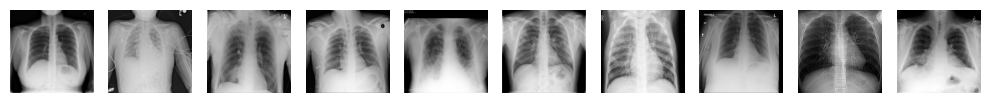

In [18]:
import torchshow as ts
x = torch.stack([data_train[i][0] for i in range(10)]).to(device)
ts.show(x, nrows=1, figsize=(10, 2))

In [19]:
import torch.utils.data
from torch.utils.data import random_split


num_samples = len(data_train)
num_test = int(0.2 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 21600 
 Test len: 5400


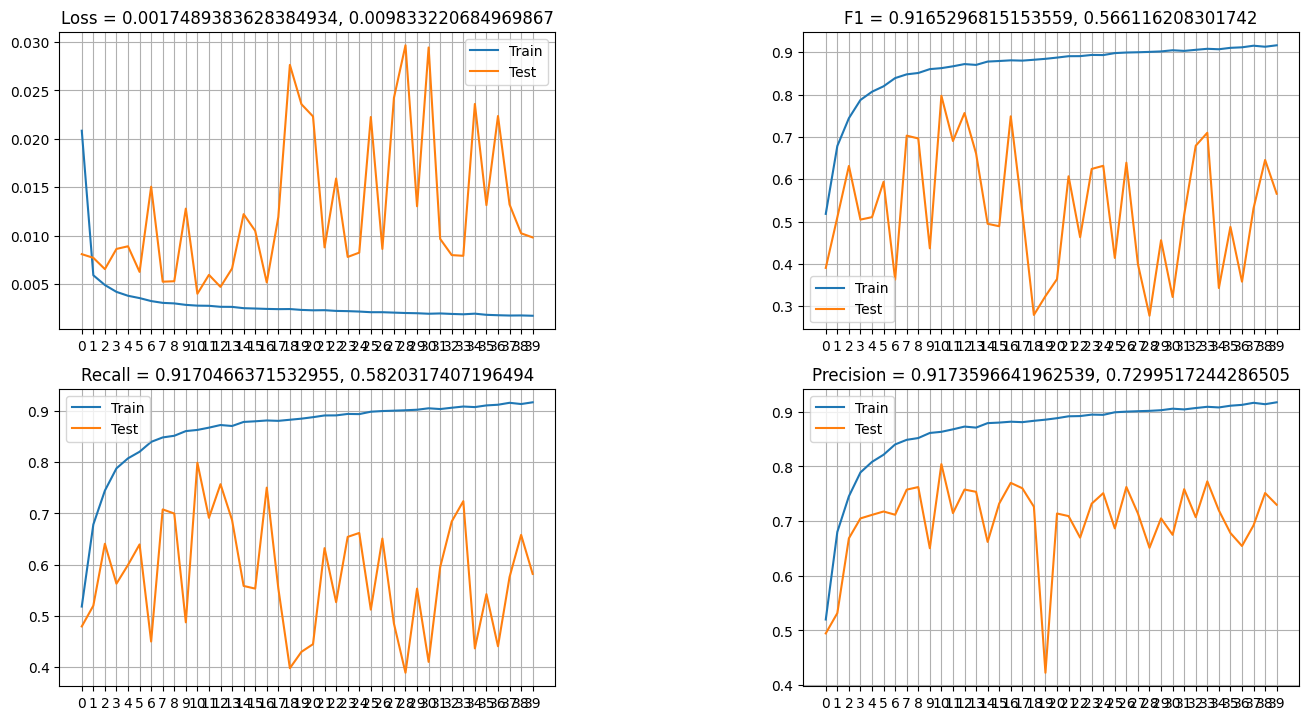

In [20]:
batch_size = 128
num_epochs = 40 # 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(alex_net_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

In [21]:
alex_net_model.load_state_dict(torch.load('C:/Users/sasha/Desktop/проекты/YML NN/walexnetmodmaxf1.pth', map_location=torch.device('cpu')))


<All keys matched successfully>

In [22]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import Compose, PILToTensor, ToDtype, Normalize
from torchvision import datasets, transforms
import os
from PIL import Image
import pandas as pd
from tqdm import tqdm
from sklearn.metrics import f1_score, recall_score, precision_score
import torch.nn.functional as F


class CustomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path).convert('RGB')
                
        if self.transform:
            image = self.transform(image)

        return image


transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

data_main_test = CustomDataset(root_dir='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/test_images', transform=transform)
test_loader = DataLoader(data_main_test)

In [25]:
data = []

alex_net_model.eval()
#model.eval()

with torch.no_grad():
    for i in range(len(data_main_test)):
        inp = data_main_test[i].clone().detach()
        inp = inp.unsqueeze(0)
        inp = inp.to(device)
        #mask = model(inp)
        #img = inp * mask[0]
        output = alex_net_model(inp)
        
        
        predicted_id =  torch.argmax(F.softmax(output, dim=1)).item()
        data.append([i, predicted_id])
        if i % 1000 == 0:
            print(i)
        

df = pd.DataFrame(data)
 
file_path = 'answerslate1.csv'

df.columns = ['id', 'target_feature']
df.to_csv(file_path, index=False, header=True)

print(f'CSV file saved to: {file_path}')


0
1000
2000
3000
4000
5000
6000
CSV file saved to: answerslate1.csv
